In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, accuracy_score

dfcsv = pd.read_csv("/content/drive/MyDrive/ML PROJ101/coral_clean_sea.csv")

columns_to_drop = ['sample_id', 'site_id', 'date', 'percent_bleaching', 'bleach_class', 'is_sea', 'is_thailand','data_source']
df = dfcsv.drop(columns=[col for col in columns_to_drop if col in dfcsv.columns], errors='ignore')

df.head()

,country_name,tsa_dhw,ssta_dhw,tsa,ssta,ssta_frequency,tsa_frequency,climsst,temperature_c,temperature_maximum,...,exposure,cyclone_frequency,windspeed,latitude_degrees,longitude_degrees,ocean_name,realm_name,date_year,date_month,bleached
0,Indonesia,0.00,10.95,0.51,1.37,12.00,4.00,29.19,30.46,32.52,...,Sheltered,48.13,2.0,-5.5167,106.4833,Pacific,Central Indo-Pacific,1983,3,1
1,Thailand,0.28,2.27,-0.11,0.58,4.20,0.20,NaN,30.29,33.66,...,Sheltered,47.87,3.0,8.0000,98.3333,Indian,Western Indo-Pacific,1990,3,1
2,Thailand,0.00,2.14,0.19,0.80,3.50,0.00,NaN,30.34,33.55,...,Sheltered,47.86,3.0,8.1042,98.3028,Indian,Western Indo-Pacific,1990,3,1
3,Thailand,10.10,11.75,0.96,1.02,17.25,5.75,NaN,31.11,33.55,...,Sheltered,47.86,3.0,8.1040,98.3020,Indian,Western Indo-Pacific,1991,5,1
4,Thailand,8.63,11.48,1.18,2.21,12.00,4.00,29.49,31.90,34.89,...,Sheltered,48.00,3.0,8.0000,98.5000,Indian,Western Indo-Pacific,1991,7,1


In [12]:
df_clean = df.dropna().copy()

target_col = df_clean.columns[-1]

X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

X_encoded = pd.get_dummies(X, drop_first=True)

print(f"จำนวนแถวหลังดรอป NaN: {df_clean.shape[0]}")
print(f"จำนวนฟีเจอร์หลังจากทำ One-Hot Encoding: {X_encoded.shape[1]}")
display(X_encoded.head())

จำนวนแถวหลังดรอป NaN: 3921
จำนวนฟีเจอร์หลังจากทำ One-Hot Encoding: 30


,tsa_dhw,ssta_dhw,tsa,ssta,ssta_frequency,tsa_frequency,climsst,temperature_c,temperature_maximum,turbidity,...,country_name_Indonesia,country_name_Malaysia,country_name_Myanmar,country_name_Philippines,country_name_Thailand,country_name_Vietnam,exposure_Sheltered,exposure_Sometimes,ocean_name_Pacific,realm_name_Western Indo-Pacific
0,0.00,10.95,0.51,1.37,12.0,4.0,29.19,30.46,32.52,0.0743,...,True,False,False,False,False,False,True,False,True,False
5,0.00,0.00,-0.62,-0.05,3.0,0.0,29.27,29.43,33.01,0.1533,...,False,False,False,True,False,False,True,False,True,False
6,6.59,8.14,0.34,0.53,6.0,4.0,29.43,30.38,32.48,0.0517,...,False,False,False,False,True,False,True,False,False,True
7,4.39,5.78,1.22,1.38,5.0,3.0,29.46,31.18,32.43,0.0491,...,False,False,False,False,True,False,True,False,False,True
21,1.23,5.75,-1.74,-1.20,6.0,4.0,29.35,27.75,32.64,0.0493,...,True,False,False,False,False,False,False,False,True,False


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print(f"Train set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Train set shape: (3136, 30)
Test set shape: (785, 30)


In [14]:
# Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("=== Decision Tree Classifier Report ===")
print(classification_report(y_test, dt_pred))
print(f"Accuracy: {accuracy_score(y_test, dt_pred):.4f}")

# Random Forest
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("\n=== Random Forest Classifier Report ===")
print(classification_report(y_test, rf_pred))
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}")

=== Decision Tree Classifier Report ===
              precision    recall  f1-score   support

           0       0.81      0.80      0.81       529
           1       0.60      0.61      0.61       256

    accuracy                           0.74       785
   macro avg       0.71      0.71      0.71       785
weighted avg       0.74      0.74      0.74       785

Accuracy: 0.7414

=== Random Forest Classifier Report ===
              precision    recall  f1-score   support

           0       0.84      0.88      0.86       529
           1       0.72      0.67      0.69       256

    accuracy                           0.81       785
   macro avg       0.78      0.77      0.78       785
weighted avg       0.80      0.81      0.81       785

Accuracy: 0.8076


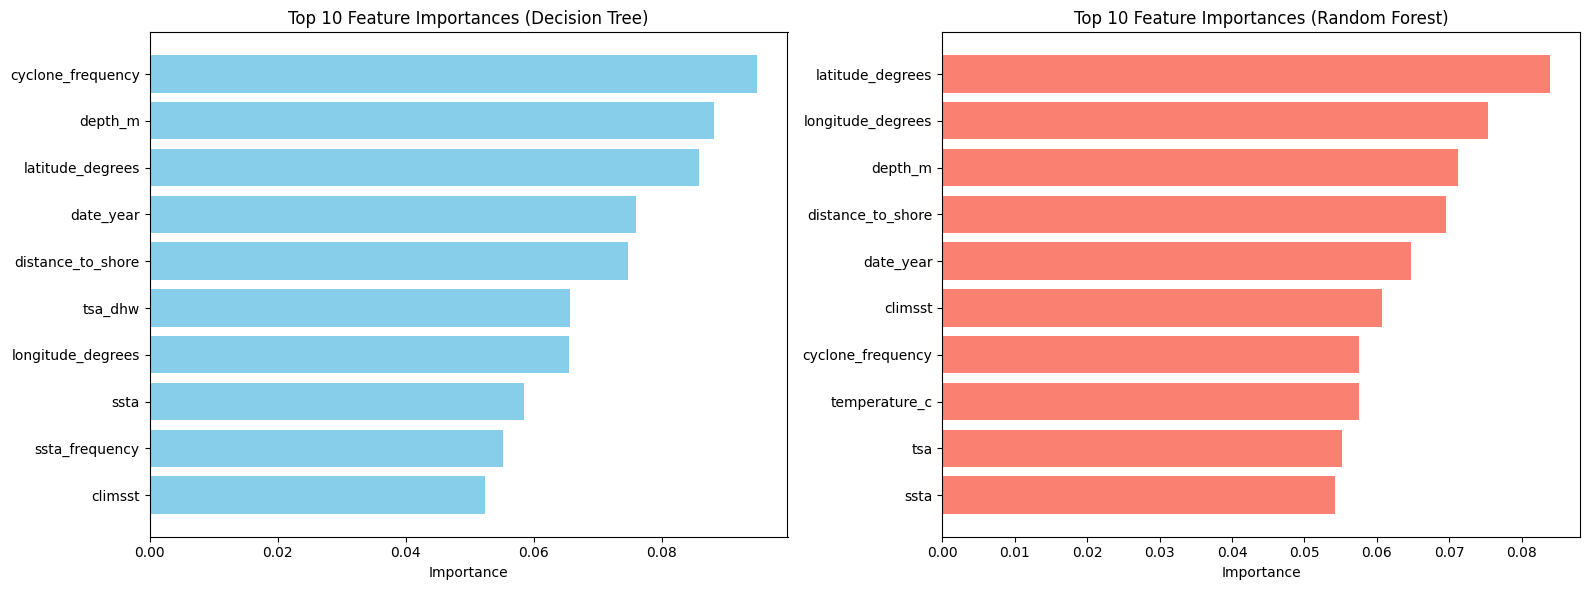

In [15]:
import matplotlib.pyplot as plt

dt_importances = dt_model.feature_importances_
rf_importances = rf_model.feature_importances_
features = X_encoded.columns

indices_dt = np.argsort(dt_importances)[::-1][:10]
indices_rf = np.argsort(rf_importances)[::-1][:10]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(range(10), dt_importances[indices_dt][::-1], align='center', color='skyblue')
axes[0].set_yticks(range(10))
axes[0].set_yticklabels([features[i] for i in indices_dt][::-1])
axes[0].set_title('Top 10 Feature Importances (Decision Tree)')
axes[0].set_xlabel('Importance')

axes[1].barh(range(10), rf_importances[indices_rf][::-1], align='center', color='salmon')
axes[1].set_yticks(range(10))
axes[1].set_yticklabels([features[i] for i in indices_rf][::-1])
axes[1].set_title('Top 10 Feature Importances (Random Forest)')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

In [16]:
!pip install shap

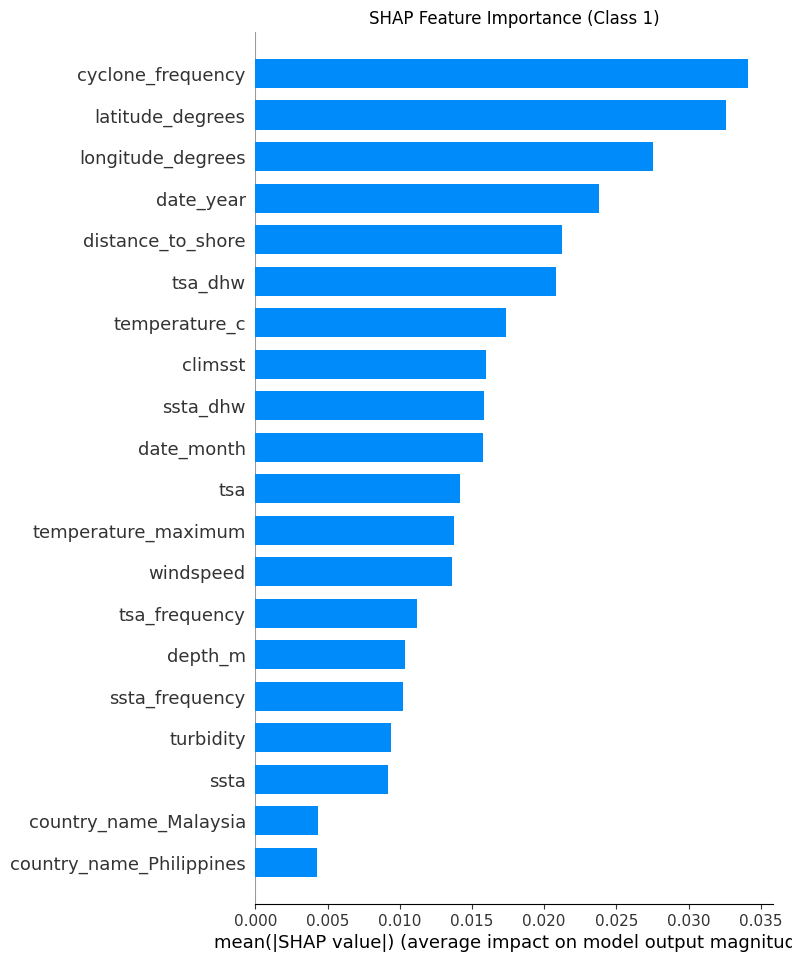

In [17]:
import shap

explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(X_test.iloc[:100])

shap_values_class1 = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values[1]

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test.iloc[:100], plot_type="bar", show=False)
plt.title("SHAP Feature Importance (Class 1)")
plt.show()

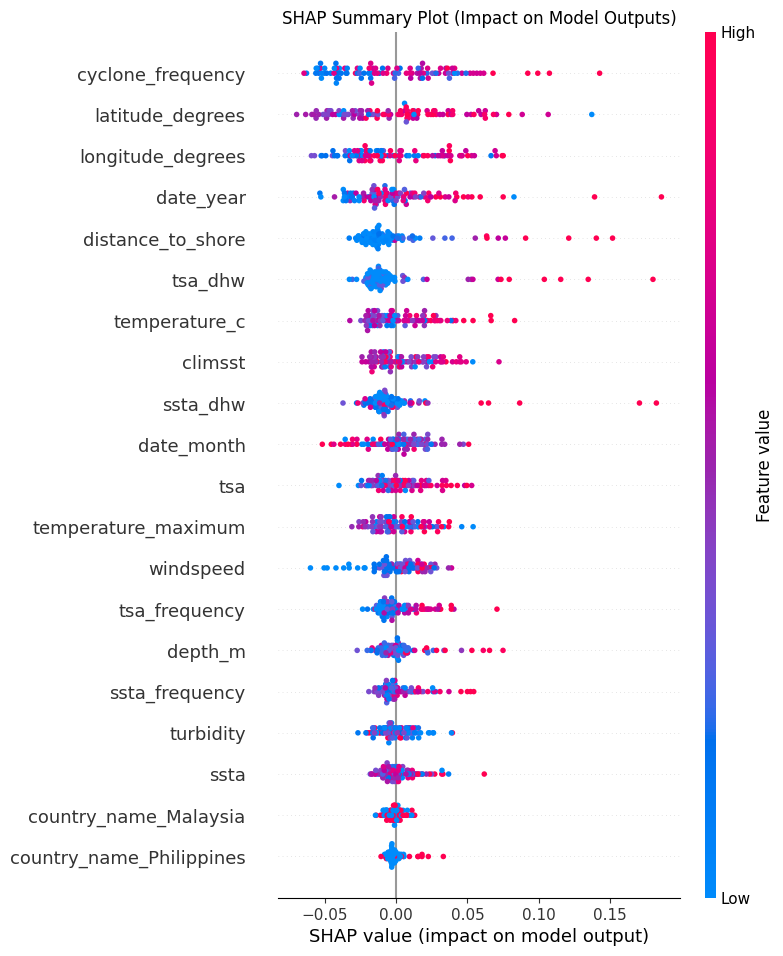

In [18]:
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_class1, X_test.iloc[:100], show=False)
plt.title("SHAP Summary Plot (Impact on Model Outputs)")
plt.show()